In [1]:
import numpy as np
import torch
from sklearn.datasets import load_sample_images

import torchvision
import torchvision.transforms.v2 as T

In [2]:
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

device

'cpu'

In [3]:
import matplotlib.pyplot as plt

plt.rc("font", size=14)
plt.rc("axes", labelsize=14, titlesize=14)
plt.rc("legend", fontsize=14)
plt.rc("xtick", labelsize=10)
plt.rc("ytick", labelsize=10)


In [4]:
sample_images = np.stack(load_sample_images()["images"])
sample_images = torch.tensor(sample_images, dtype=torch.float32) / 255
sample_images.shape

torch.Size([2, 427, 640, 3])

In [5]:
# permute the dimension to (B, H, W, C) to (B, C, H, W)
sample_images_permuted = sample_images.permute(0, 3, 1, 2)
sample_images_permuted.shape

torch.Size([2, 3, 427, 640])

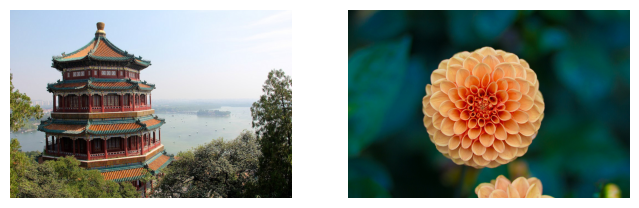

In [6]:
def plot_image(img):
    plt.imshow(img.permute(1, 2, 0))
    plt.axis('off')

plt.figure(figsize=(8, 4))
for idx, img in enumerate(sample_images_permuted):
    plt.subplot(1, 2, idx + 1)
    plot_image(img)

In [7]:
# crop the images to center 
cropped_images = T.CenterCrop((70, 120))(sample_images_permuted)
cropped_images.shape

torch.Size([2, 3, 70, 120])

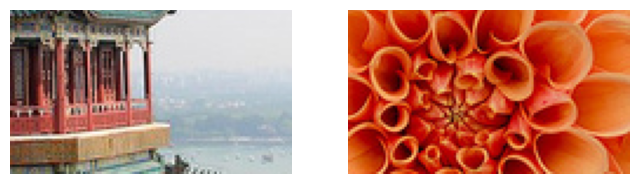

In [8]:
plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plot_image(cropped_images[0])
plt.subplot(1, 2, 2)
plot_image(cropped_images[1])

In [9]:
import torch.nn as nn
conv_layer = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=7,)
fmaps = conv_layer(cropped_images)
fmaps.shape, conv_layer.weight.shape, conv_layer.bias.shape

(torch.Size([2, 32, 64, 114]), torch.Size([32, 3, 7, 7]), torch.Size([32]))

In [10]:
conv_layer = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=7,padding='same')
fmaps = conv_layer(cropped_images)
fmaps.shape, conv_layer.weight.shape, conv_layer.bias.shape

(torch.Size([2, 32, 70, 120]), torch.Size([32, 3, 7, 7]), torch.Size([32]))

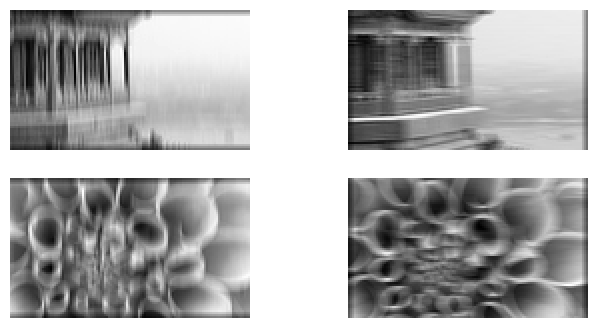

In [11]:
# let's create the two filter with vertical and horizontal for img to highlight the features
import torch.nn.functional as F 

plt.figure(figsize=(8, 4))
filters = torch.zeros([2, 3, 7, 7])
biases = torch.zeros([2])

# making vertical and horizontal filters for highlighing the features
filters[0, :, :, 3] = 1
filters[1, :, 3, :] = 1

fmaps = F.conv2d(cropped_images, filters, biases, stride=1, padding='same')


for image_idx in (0, 1):
    for fmap_idx in (0, 1):
        plt.subplot(2, 2, image_idx * 2 + fmap_idx + 1)
        plt.imshow(fmaps[image_idx, fmap_idx], cmap='gray')
        plt.axis('off')

plt.show()


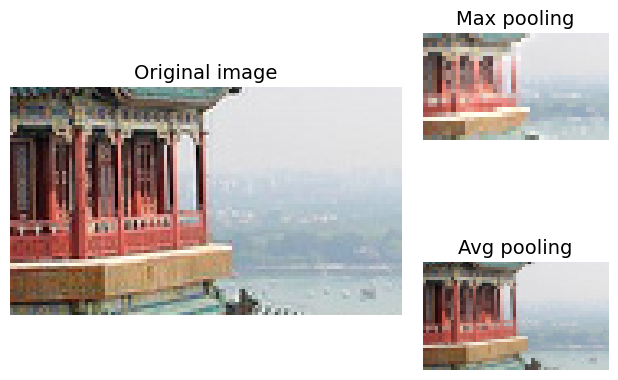

In [12]:
# Maximum Pooling Layer 
max_pool = nn.MaxPool2d(kernel_size=3)
output_max_pool = max_pool(cropped_images)

# Average Pooling Layer
avg_pool = nn.AvgPool2d(kernel_size=2)
output_avg_pool = avg_pool(cropped_images)


# Global Average Pooling Layer 
global_avg_pool = nn.AvgPool2d(kernel_size=(70, 120))
global_avg_pool_output = global_avg_pool(cropped_images)

# Adaptive Average Pooling Layer 
adv_avg_pool = nn.AdaptiveAvgPool2d(output_size=1)
adv_avg_pool_output = adv_avg_pool(cropped_images)



ax1 = plt.subplot2grid((2, 3), (0, 0), rowspan=2, colspan=2)
ax1.imshow(cropped_images[0].permute(1, 2, 0))
ax1.axis('off')
ax1.set_title("Original image")

ax2 = plt.subplot2grid((2, 3), (0, 2))
ax2.imshow(output_max_pool[0].permute(1, 2, 0))
ax2.axis('off')
ax2.set_title("Max pooling")

ax3 = plt.subplot2grid((2, 3), (1, 2))
ax3.imshow(output_avg_pool[0].permute(1, 2, 0))
ax3.axis('off')
ax3.set_title("Avg pooling")


# ax4 = plt.subplot2grid((3, 3), (2, 1))
# ax4.imshow(global_avg_pool_output[0].permute(1, 2, 0))
# ax4.axis('off')
# ax4.set_title("Global Avg pooling")

# ax5 = plt.subplot2grid((3, 3), (2, 2))
# ax5.imshow(adv_avg_pool_output[0].permute(1, 2, 0))
# ax5.axis('off')
# ax5.set_title("Adaptive Avg pooling")

plt.tight_layout()
plt.show()

In [13]:
# Tackling the Fashsion MNIST cnn

from functools import partial 

torch.manual_seed(32)

DefaultConv2d = partial(nn.Conv2d, kernel_size=3, padding='same')

model = nn.Sequential(
    DefaultConv2d(in_channels=1, out_channels=64, kernel_size=7), nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),
    DefaultConv2d(in_channels=64, out_channels=128, kernel_size=7), nn.ReLU(),
    DefaultConv2d(in_channels=64, out_channels=128, kernel_size=7), nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),
    DefaultConv2d(in_channels=128, out_channels=256, kernel_size=7), nn.ReLU(),
    DefaultConv2d(in_channels=128, out_channels=256, kernel_size=7), nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),
    nn.Flatten(),
    nn.Linear(in_features=2304, out_features=128), nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(in_features=128, out_features=64), nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(in_features=64, out_features=10) 
    
    ).to(device)


In [14]:
import torchmetrics

def evaluate_tm(model, data_loader, metric):
    model.eval()
    metric.reset()
    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            metric.update(y_pred, y_batch)
    return metric.compute()

def train(model, optimizer, loss_fn, metric, train_loader, valid_loader, n_epochs):

    history = {"train_losses":[], "train_metric":[], "valid_metric":[]}

    for epoch in range(n_epochs):

        total_loss = 0.0
        metric.reset()
        model.train()

        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            loss = loss_fn(y_pred, y_batch)
            total_loss += loss.item()
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
            metric.update(y_pred, y_batch)
        
        history["train_losses"].append(total_loss / len(train_loader))
        history["train_metric"].append(metric.compute().item())
        history["valid_metric"].append(
            evaluate_tm(model, valid_loader, metric).item())
        
        print(f"Epoch {epoch + 1}/{n_epochs}, "
        f"train loss: {history['train_losses'][-1]:.4f}, "
        f"train metric: {history['train_metrics'][-1]:.4f}, "
        f"valid metric: {history['valid_metrics'][-1]:.4f}")

    return history

In [16]:
toTensor = T.Compose([T.ToImage(), T.ToDtype(torch.float32, scale=True)])

train_and_valid_data = torchvision.datasets.MNIST(
    root='datasets', train=True, download=True, transform=toTensor)
test_data = torchvision.datasets.FashionMNIST(
    root='datasets', train=False, download=True, transform=toTensor)

torch.manual_seed(32)
train_data, valid_data = torch.utils.data.random_split(
    train_and_valid_data, [55_000, 5_000]
)

100%|██████████| 9.91M/9.91M [02:22<00:00, 69.6kB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 33.0kB/s]
100%|██████████| 1.65M/1.65M [00:25<00:00, 64.0kB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.98MB/s]
100%|██████████| 26.4M/26.4M [05:04<00:00, 86.7kB/s]
100%|██████████| 29.5k/29.5k [00:01<00:00, 19.5kB/s]
100%|██████████| 4.42M/4.42M [01:35<00:00, 46.3kB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 13.8MB/s]


In [17]:
from torch.utils.data import DataLoader

torch.manual_seed(42)
train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
valid_loader = DataLoader(valid_data, batch_size=32)
test_loader = DataLoader(test_data, batch_size=32)

In [19]:
# n_epochs = 20
# optimizer = torch.optim.AdamW(model.parameters())
# xentropy = nn.CrossEntropyLoss()
# accuracy = torchmetrics.Accuracy(task="multiclass", num_classes=10).to(device)
# # history = train(model, optimizer, xentropy, accuracy,
#                 train_loader, valid_loader, n_epochs)

In [29]:
# Lenet5 - Architecture

lenet5_model = nn.Sequential(
    nn.Conv2d(in_channels=1, out_channels=6, kernel_size=5),
    nn.ReLU(),
    nn.AvgPool2d(kernel_size=2, stride=2),
    nn.Conv2d(in_channels=6, out_channels=16, kernel_size=5),
    nn.ReLU(),
    nn.AvgPool2d(kernel_size=2, stride=2),
    nn.Flatten(),
    nn.Linear(in_features=16 * 4 * 4, out_features=120),
    nn.ReLU(),
    nn.Linear(in_features=120, out_features=84),
    nn.ReLU(),
    nn.Linear(in_features=84, out_features=10),
    nn.Softmax()
).to(device)


In [30]:
# Lenet5 - Architecture
for X_batch, y_batch in train_loader:
    print("X", X_batch.shape)
    print("y", y_batch.shape)
    y_pred = lenet5_model(X_batch)
    print("y_pred", y_pred.shape)
    break

X torch.Size([32, 1, 28, 28])
y torch.Size([32])
y_pred torch.Size([32, 10])


/home/itxkakar/Personal /Coding Playground/Hands-on-Machine-Learning/.venv/lib/python3.12/site-packages/torch/nn/modules/module.py:1779: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  return self._call_impl(*args, **kwargs)


In [ ]:
alex_net = nn.Sequential(
    nn.Conv2d(in_channels=1, out_channels=96, kernel_size=11, stride=4),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),
    nn.ReLU(),
    nn.Conv2d(in_channels=96, out_channels=256, kernel_size=5, stride=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),
    nn.Conv2d(in_channels=256, out_channels=384, kernel_size=3, stride=1),
    nn.ReLU(),
    nn.Conv2d(in_channels=384, out_channels=384, kernel_size=3, stride=1),
    nn.ReLU(),
    nn.Conv2d(in_channels=384, out_channels=256, kernel_size=3, stride=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),
    nn.Flatten(),
    nn.Linear(in_features=6 * 6 * 256, out_features=4096),
    nn.ReLU(),
    nn.Linear(in_features=4096, out_features=4096),
    nn.ReLU(),
    nn.Linear(in_features=4096, out_features=10),
    nn.Softmax()    
)

In [ ]:
alex_net = nn.Sequential(
    nn.Conv2d(in_channels=1, out_channels=96, kernel_size=5, stride=1, padding=2),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),
    nn.Conv2d(in_channels=96, out_channels=256, kernel_size=3, stride=1, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),
    nn.Conv2d(in_channels=256, out_channels=384, kernel_size=3, stride=1, padding=1),
    nn.ReLU(),
    nn.Conv2d(in_channels=384, out_channels=384, kernel_size=3, stride=1, padding=1),
    nn.ReLU(),
    nn.Conv2d(in_channels=384, out_channels=256, kernel_size=3, stride=1, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),
    nn.Flatten(),
    nn.Linear(in_features=256 * 3 * 3, out_features=4096),
    nn.ReLU(),
    nn.Linear(in_features=4096, out_features=4096),
    nn.ReLU(),
    nn.Linear(in_features=4096, out_features=10),
    nn.Softmax(dim=1)    
).to(device)

In [54]:
# Alexnet - Architecture
for X_batch, y_batch in train_loader:
    print("X", X_batch.shape)
    print("y", y_batch.shape)
    y_pred = alex_net(X_batch)
    print("y_pred", y_pred.shape)
    break

X torch.Size([32, 1, 28, 28])
y torch.Size([32])
y_pred torch.Size([32, 10])
